# GEFS v12 → dHBV → CRPS/CRPSS (continuous simulation only)

- `gefs_crpss.py`: NPZ forecast and simulation storage, temporal alignment, CRPS equations, CRPSS, deterministic scores, figures/CSV.
- `tempfunctions.py`: underlying HBV simulation, GEFS forcing, restart, and corrections (unchanged).

**Array dimensions:** saved GEFS forecast `(M,L)`; loaded forecasts `(I,L,M)`; simulation dates/flow `(T,)`; aligned simulated targets `(I,L)`; prior-day simulated flow `(I,)`; CRPS cases `(I,L)`; mean score by lead `(L,)`.

With `LEAD1_OFFSET=0`, GEFS Day 1 verifies on initialization date and the persistence reference comes from the previous day's continuous simulated streamflow. If GEFS `.npz` files already exist, leave `RUN_FORECASTS=False`; continuous simulations are generated or loaded in their own cell.


## 1. Load configuration and dataset

The data loader supplies the HBV model inputs, total number of daily timesteps, and basin-column ordering. 

In [2]:
import sys
sys.path.append('../../') 
from src.dmg import ModelHandler 
from src.dmg.core.utils import import_data_loader, print_config, print_dataset_info, set_randomseed
from tempfunctions import *
from example import load_config 
#------------------------------------------#
# Define model settings here.
from tempfunctions import get_config_path

MODEL_TYPE = "d3"   # change only this: "d3", "d2", or "static"
CONFIG_PATH = get_config_path(MODEL_TYPE)
#------------------------------------------#

# 1. Load configuration dictionary of model parameters and options.
config = load_config(CONFIG_PATH)
config['mode'] = 'sim'

print_config(config)
# print("Config Keys:", config.keys())
# print("config['multimodel_type']", config['multimodel_type'])
# Set random seed for reproducibility.
set_randomseed(config['seed'])

# 2. Initialize the differentiable HBV 1.1p model (LSTM + HBV 1.1p).
model = ModelHandler(config, verbose=True) # model key is ['Hbv_1_1p'] 
nn_model = model.model_dict["Hbv_1_1p"].nn_model

# 3. Load and initialize a dataset dictionary of NN and HBV model inputs.
data_loader_cls = import_data_loader(config['data_loader'])
data_loader = data_loader_cls(config, test_split=False, overwrite=False)
print_dataset_info(data_loader.dataset)    


Current Configuration
  Experiment Mode:    sim                 
  Model 1:            Hbv_1_1p            
  Dynamic Params:     ['parBETA', 'parK0', 'parBETAET']

Data Loader
  Data Source:        camels_531          
  Simulation Range :  2009/10/01          2013/09/30          

Experiment Parameters
  Train Epochs:       100                 Batch Size:         100                 
  Start Epoch:        0                   Save Epoch:         5                   
  Loss Fn:            NseBatchLoss        
  Optimizer:          Adadelta            LR Scheduler:       None                

Machine
  Device:             cuda:0              
  Dtype:              torch.float32       


Dataset Inputs
Dataset key    Shape               Description
------------------------------------------------------------
x_phy          (1461, 531, 3)       # [time, basin, forcing_features]
c_phy          (531, 0)             # [basin, attr_features] (no physical attributes here)
x_nn           (1461

## 2. Experiment settings and basin selection

`MODE` selects one or many basins for both forecast generation and simulated-reference evaluation. `CLIMATOLOGY_YEARS=None` uses the full continuous simulation, including dates in the test period. Set it to historical years for out-of-sample climatology.

In [38]:
# Forecast experiment and dataset conventions
START_DATE, END_DATE = "2012-01-01", "2012-12-31"
YEAR = 2012
PRE, WINDOW, POST = "scalar", 30, True
N_LEADS, N_ENSEMBLES, WARMUP = 10, 5, 365
LEAD1_OFFSET = 0       # GEFS Day 1 is the initialization date
MIN_VALID_CASES = 30 
CLIMATOLOGY_YEARS = None  # Original scores; or [2010, 2011] for pre-2012 climatology

MODE = "multiple"         # "single" or "multiple"
BASIN_SET = "best_36" # "best_36", "camels_531", "all_loaded"

SINGLE_BASIN_ID = "01031500" # "14306500" #"01139000" # "01137500"
SKIP_EXISTING = True # false if you want to overwrite the short-time forecast testings of certain basins, true if you want to skip

gage_ids = np.load(config["observations"]["gage_info"], allow_pickle=True)
subset_file = config["observations"]["subset_path"]
with open(subset_file, "r") as f:
    raw_subset = f.read().strip()
gage_ids_subset = (
    json.loads(raw_subset) if raw_subset.startswith("[")
    else np.loadtxt(subset_file, dtype=int).reshape(-1).tolist()
)

obs_name = config["observations"]["name"]
if obs_name == "camels_671":
    loader_basin_pool = [int(b) for b in gage_ids]
elif obs_name == "camels_531":
    loader_basin_pool = [int(b) for b in gage_ids_subset]
else:
    raise ValueError(f"Unexpected CAMELS observations name: {obs_name}")

if MODE == "single":
    eval_basins = [int(SINGLE_BASIN_ID)]
elif MODE == "multiple":
    if BASIN_SET == "best_36":
        eval_basins = [
            int(b) for b in tempfunctions.selectbasins()
        ]
    elif BASIN_SET == "camels_531":
        eval_basins = [
            int(b) for b in gage_ids_subset
        ]
    elif BASIN_SET == "all_loaded":
        eval_basins = list(loader_basin_pool)
    else:
        raise ValueError(f"Unknown BASIN_SET: {BASIN_SET}")
else:
    raise ValueError(f"Unknown MODE: {MODE}")

missing = sorted(set(eval_basins).difference(loader_basin_pool))
if missing:
    raise ValueError(f"Basins not in data-loader ordering: {missing}")

save_root = gefs.forecast_root(config, START_DATE, END_DATE, PRE, WINDOW, POST)
print("# of selected basins for evaluation:", len(eval_basins))
print("Saved to forecast folder:", save_root) 

# of selected basins for evaluation: 36
Saved to forecast folder: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True


## 3. Generate year-long short-time forecasts and save daily NPZ forecasts

Set `RUN_FORECASTS=True` and rerun this cell **only** to generate missing short-time forecasts. Generation calls `tempfunctions.run_segment()` and `tempfunctions.run_warm_forecasts_restart()` for each date; `.npz` saving is performed by `gefs.save_forecast_npz()`. Existing `.npz` forecasts remain unchanged when `SKIP_EXISTING=True`.

**IMPORTANT:** The original `tempfunctions` GEFS restart callback assumes a bias correction (`PRE="scalar"` or `"cdf"`). This notebook uses `"scalar"`.  

In [39]:
RUN_FORECASTS = False    # False if reuse .npz short-time forecasts 

if RUN_FORECASTS:
    model = ModelHandler(config, verbose=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    gefs_results, failed_basins = {}, {}

    for position, gage_id in enumerate(eval_basins, start=1):
        print(f"Basin {position}/{len(eval_basins)}: {gage_id:08d}")
        try:
            result = gefs.run_gefs_one_year(
                GAGE_ID=gage_id,
                model=model,
                data_loader=data_loader,
                config=config,
                basin_pool=loader_basin_pool,  # ORDER MUST MATCH data_loader
                startid_endid=tempfunctions.startid_endid,
                run_segment=tempfunctions.run_segment,
                run_warm_forecasts_restart=tempfunctions.run_warm_forecasts_restart,
                post_processing=tempfunctions.post_processing,
                START_DATE=START_DATE, END_DATE=END_DATE,
                FORECAST=N_LEADS, N_ENSEMBLES=N_ENSEMBLES, WARMUP=WARMUP,
                WINDOW=WINDOW, PRE=PRE, POST=POST,
                device=device, skip_existing=SKIP_EXISTING,
            )
            gefs_results[gage_id] = result
            if result["n_failed"]:
                failed_basins[gage_id] = result["failed_dates"]
        except Exception as exc:
            failed_basins[gage_id] = str(exc)
            print(f"FAILED {gage_id:08d}: {exc}")

    gefs.print_gefs_summary(eval_basins, gefs_results, failed_basins)
else:
    print("Skipped HBV short-time forecast generation; existing NPZ files will be used.")

Skipped HBV short-time forecast generation; existing NPZ files will be used.


## 4. Create cache continuous Daymet–HBV simulations

`build_basin_results()` creates the dated basin records without extracting observed discharge. The next cell attaches `sim` for **every selected basin**, generating or loading a trusted cached continuous Daymet–HBV simulation. This is to generate the simulaton forecast data for computing CRPSS_ref,ad.

In [40]:
basin_results = gefs.build_basin_results(
    data_loader=data_loader,
    config=config,
    loader_basin_pool=loader_basin_pool,
    selected_basins=eval_basins,
    WARMUP=WARMUP,
)
print("Observation data prepared for", len(basin_results), "basin")

Observation data prepared for 36 basin


In [41]:
import numpy as np
import pandas as pd
import torch
from pathlib import Path 

RUN_CONTINUOUS_SIM = False  # True if you want to generate continuous HBV simulations if not cached before 

SIM_DIR = Path(config["sim_dir"]) / "continuous_daymet_reference"
SIM_DIR.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
reference_model = None
 
for gage_id in eval_basins:
    gage_id = int(gage_id)
    basin_key = f"{gage_id:08d}"
    basin_idx = loader_basin_pool.index(gage_id)
    save_path = SIM_DIR / f"reference_{basin_key}.npz"
    expected_dates = pd.DatetimeIndex(basin_results[basin_key]["dates"]).normalize()

    if save_path.exists():
        # Older user-generated cache files stored object-typed dates.
        # Only enable legacy pickle loading for files you created and trust.
        qsim, saved_dates, saved_basin = gefs.load_simulation_npz(
            save_path, allow_legacy_pickle=True
        )
        if saved_basin != basin_key or not saved_dates.equals(expected_dates):
            raise ValueError(f"{basin_key}: cached simulation basin/date mismatch")
        print(f"Loaded previously-cached continuous HBV simulation: {basin_key}")

        # Convert trusted older cache to native datetime64[D]; subsequent reads
        # can use allow_legacy_pickle=False. No HBV computation required.
        with np.load(save_path, allow_pickle=True) as cache:
            old_dates = (cache["dates"].dtype == object)
        if old_dates:
            gefs.save_simulation_npz(save_path, basin_key, saved_dates, qsim)
            print(f"Converted legacy dates to safe dtype: {basin_key}")

    elif RUN_CONTINUOUS_SIM:
        if reference_model is None:
            reference_model = ModelHandler(config, verbose=True)
            reference_model.eval()
            # Verify that this handler uses your intended calibrated checkpoint.

        qsim = tempfunctions.run_segment(
            model=reference_model,
            dataset=data_loader.dataset,
            basin_idx=basin_idx,
            device=device,
            start_idx=None,
            end_idx=None,
            warm_up=WARMUP,
            cache_states=False,
            warm_up_states=True,
        )
        qsim = np.asarray(qsim, dtype=float).reshape(-1)
        n_total = data_loader.dataset["target"].shape[0]
        if len(qsim) == n_total:
            # Only trim when run_segment returned the entire input length.
            qsim = qsim[WARMUP:]
        if len(qsim) != len(expected_dates):
            raise ValueError(
                f"{basin_key}: qsim length {len(qsim)} != "
                f"expected {len(expected_dates)}"
            )
        gefs.save_simulation_npz(save_path, basin_key, expected_dates, qsim)
        print(f"Saved continuous simulation: {basin_key}")
    else:
        raise FileNotFoundError(f"Missing continuous simulation: {save_path}")

    if qsim.shape != (len(expected_dates),):
        raise ValueError(f"{basin_key}: invalid qsim shape {qsim.shape}")
    basin_results[basin_key]["sim"] = qsim
    print(f"{basin_key}: sim={qsim.shape}, dates={expected_dates[0].date()} to {expected_dates[-1].date()}")

print("All selected basins for evaluation have done continuous simulated reference flow.")

Loaded previously-cached continuous HBV simulation: 01073000
01073000: sim=(1096,), dates=2010-10-01 to 2013-09-30
Loaded previously-cached continuous HBV simulation: 01078000
01078000: sim=(1096,), dates=2010-10-01 to 2013-09-30
Loaded previously-cached continuous HBV simulation: 01539000
01539000: sim=(1096,), dates=2010-10-01 to 2013-09-30
Loaded previously-cached continuous HBV simulation: 01487000
01487000: sim=(1096,), dates=2010-10-01 to 2013-09-30
Loaded previously-cached continuous HBV simulation: 02177000
02177000: sim=(1096,), dates=2010-10-01 to 2013-09-30
Loaded previously-cached continuous HBV simulation: 02350900
02350900: sim=(1096,), dates=2010-10-01 to 2013-09-30
Loaded previously-cached continuous HBV simulation: 04059500
04059500: sim=(1096,), dates=2010-10-01 to 2013-09-30
Loaded previously-cached continuous HBV simulation: 04256000
04256000: sim=(1096,), dates=2010-10-01 to 2013-09-30
Loaded previously-cached continuous HBV simulation: 03182500
03182500: sim=(1096

## 5. Generate CRPSS figures from cached NPZ files of year-long daily-initialized short-term forecasts
Note that run_gefs_crpss() reads previously generated GEFS forecast .npz files rather than rerunning the forecasting.
## 5.1 Generate CRPSS figures for single- or multiple- selected basins

[1/36] 01073000: 362 forecasts
[2/36] 01078000: 362 forecasts
[3/36] 01539000: 362 forecasts
[4/36] 01487000: 362 forecasts
[5/36] 02177000: 362 forecasts
[6/36] 02350900: 362 forecasts
[7/36] 04059500: 362 forecasts
[8/36] 04256000: 362 forecasts
[9/36] 03182500: 362 forecasts
[10/36] 03281500: 362 forecasts
[11/36] 03500000: 362 forecasts
[12/36] 03498500: 362 forecasts
[13/36] 05595730: 362 forecasts
[14/36] 05593575: 362 forecasts
[15/36] 07362100: 362 forecasts
[16/36] 08014500: 362 forecasts
[17/36] 05057200: 362 forecasts
[18/36] 05120500: 362 forecasts
[19/36] 06623800: 362 forecasts
[20/36] 06919500: 362 forecasts
[21/36] 07083000: 362 forecasts
[22/36] 07197000: 362 forecasts
[23/36] 08164300: 362 forecasts
[24/36] 08195000: 362 forecasts
[25/36] 08269000: 362 forecasts
[26/36] 08378500: 362 forecasts
[27/36] 09107000: 362 forecasts
[28/36] 09035900: 362 forecasts
[29/36] 09510200: 362 forecasts
[30/36] 09508300: 362 forecasts
[31/36] 10343500: 362 forecasts
[32/36] 10234500:

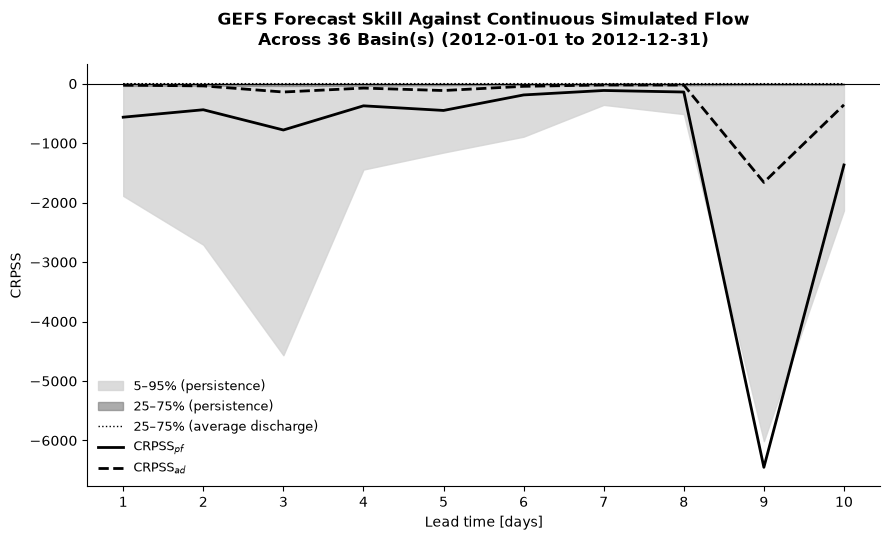

Evaluated: 36; failed: 0
Figure saved to: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_multiple/CRPSS_spatial_simulated_2012.png
CSV saved to: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_multiple/CRPSS_multiple_simulated_2012.csv


In [42]:
# Check if there is any missing continuous HVBV results saved
missing_sim = [f"{int(b):08d}" for b in eval_basins
               if "sim" not in basin_results[f"{int(b):08d}"]]
if missing_sim:
    raise ValueError(f"Missing continuous simulations for {missing_sim[:10]}")

# Run the year-long initialization dates to compute crpss
crpss_results = gefs.run_gefs_crpss(
    mode=MODE,
    config=config,
    basin_results=basin_results,
    basin_pool=eval_basins,
    GAGE_ID=eval_basins[0] if MODE == "single" else None,
    START_DATE=START_DATE, END_DATE=END_DATE,
    PRE=PRE, WINDOW=WINDOW, POST=POST,
    YEAR=YEAR, N_LEADS=N_LEADS, N_ENSEMBLES=N_ENSEMBLES,
    LEAD1_OFFSET=LEAD1_OFFSET,
    MIN_VALID_CASES=MIN_VALID_CASES,
    CLIMATOLOGY_YEARS=CLIMATOLOGY_YEARS,
    show_plot=True,
)
# display(crpss_results["results_df"])

## 5.2 Generate CRPSS figures for all available basins 
All available basins data should be the pre-generated basin folders under the path, eg. for HBV3 dynamics: znprojects/generic_deltamodel/example/hydrology/output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/..

Original basins: 36

Excluded basins: 31

Remaining basins: 5


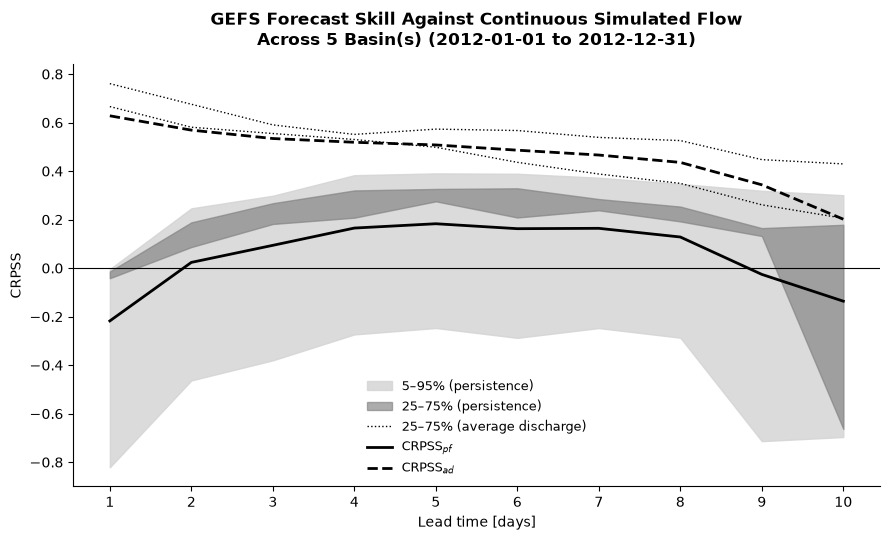


Figure saved to: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_multiple/filtered_below_(-1.5)/CRPSS_filtered.png


In [43]:
import gefs_crpss as gefs

# 0. Set the threshold to filter out outliers with extreme negative crpss value
CRPSS_THRESHOLD = -1.5
CHECK_METRICS = ["CRPSS_pf", "CRPSS_ad"] # Choose which metrics determine exclusion
 
# 1. Read existing multi-basin CRPSS results 
csv_path = Path(save_root) / "CRPSS_simulated_multiple" / f"CRPSS_multiple_simulated_{YEAR}.csv"
df = pd.read_csv(csv_path, dtype={"basin_id": str})
df["basin_id"] = df["basin_id"].str.zfill(8)
print("Original basins:", df["basin_id"].nunique())

# 2. Identify extreme basins
extreme_rows = df[df[CHECK_METRICS].lt(CRPSS_THRESHOLD).any(axis=1)]
excluded_basins = set(extreme_rows["basin_id"])
print("\nExcluded basins:", len(excluded_basins))
# print(extreme_rows[["basin_id", "lead_time"] + CHECK_METRICS].sort_values("basin_id").to_string(index=False))
 
# 3. Remove entire basins 
filtered_df = df[~df["basin_id"].isin(excluded_basins)].copy()
n_basins = filtered_df["basin_id"].nunique()
print("\nRemaining basins:", n_basins)
if n_basins == 0: raise ValueError("No basins remain. Lower the exclusion threshold.")
 
# 4. Recalculate spatial summary (NO CRPS recomputation) 
g = filtered_df.groupby("lead_time")
summary = pd.DataFrame({"lead_time": sorted(filtered_df["lead_time"].unique())})

for metric, prefix in [
    ("CRPSS_pf", "CRPSS_pf"),
    ("CRPSS_ad", "CRPSS_ad"),
]:
    grouped = g[metric]

    summary[f"{prefix}_mean"] = summary["lead_time"].map(grouped.mean())

    for percentile in [5, 25, 75, 95]:
        summary[f"{prefix}_p{percentile:02d}"] = (
            summary["lead_time"].map(
                grouped.quantile(percentile / 100)
            )
        )
        
# 5. Save filtered CSV and figure 
output_dir = csv_path.parent / f"filtered_below_({CRPSS_THRESHOLD})"
output_dir.mkdir(parents=True, exist_ok=True)
filtered_df.to_csv(output_dir / "CRPSS_filtered.csv", index=False)
summary.to_csv(output_dir / "CRPSS_summary_filtered.csv", index=False)

gefs.plot_crpss(
    summary,
    mode="multiple",
    n_basins=n_basins, 
    start_date=START_DATE,
    end_date=END_DATE,
    save_path=output_dir / "CRPSS_filtered.png",
    show_plot=True,
)
print("\nFigure saved to:", output_dir / "CRPSS_filtered.png")

## 5.3. Doublecheck the dimensions of data

In [44]:
DIAG_BASIN_ID = int(eval_basins[0])  # Select basin for detailed diagnostics

forecasts, init_dates = gefs.load_basin_forecasts(
    save_root, DIAG_BASIN_ID,
    year=YEAR, start_date=START_DATE, end_date=END_DATE,
    n_members=N_ENSEMBLES, n_leads=N_LEADS,
)
qsim_series = gefs.simulated_series(basin_results, DIAG_BASIN_ID)
target_flow, initial_flow = gefs.align_reference(
    qsim_series, init_dates, N_LEADS, LEAD1_OFFSET
)
valid = gefs.valid_forecast_cases(forecasts, target_flow, initial_flow)
crps_cases = gefs.ensemble_crps_cases(forecasts, target_flow)
ensemble_mean = np.mean(forecasts, axis=2)

print("forecasts:", forecasts.shape, "(I,L,M)")
print("init_dates:", init_dates.shape, "(I,)")
print("target_flow:", target_flow.shape, "(I,L)")
print("initial_flow:", initial_flow.shape, "(I,)")
print("crps_cases:", crps_cases.shape, "(I,L)")
print("valid by lead:", valid.sum(axis=0))
print("Direct single-case CRPS check:", gefs.crps_single(forecasts[0, 0, :], target_flow[0, 0]))
print("Array CRPS at same position:", crps_cases[0, 0])

forecasts: (362, 10, 5) (I,L,M)
init_dates: (362,) (I,)
target_flow: (362, 10) (I,L)
initial_flow: (362,) (I,)
crps_cases: (362, 10) (I,L)
valid by lead: [362 362 362 362 362 362 362 362 362 362]
Direct single-case CRPS check: 0.25298428535461426
Array CRPS at same position: 0.25298428535461426


## 6. Additional deterministic scores against continuous simulated discharge

NS, Pbias and CV use the ensemble-mean forecast


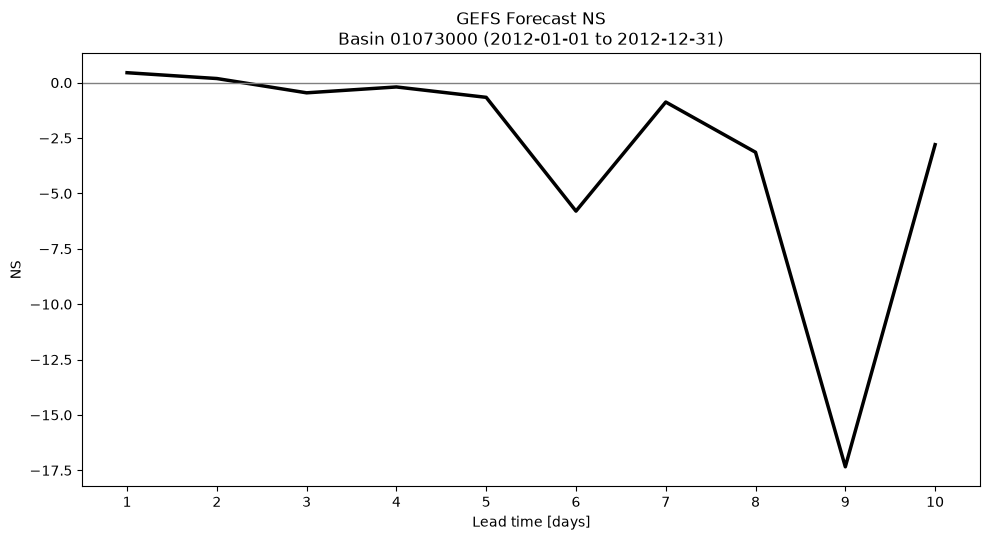

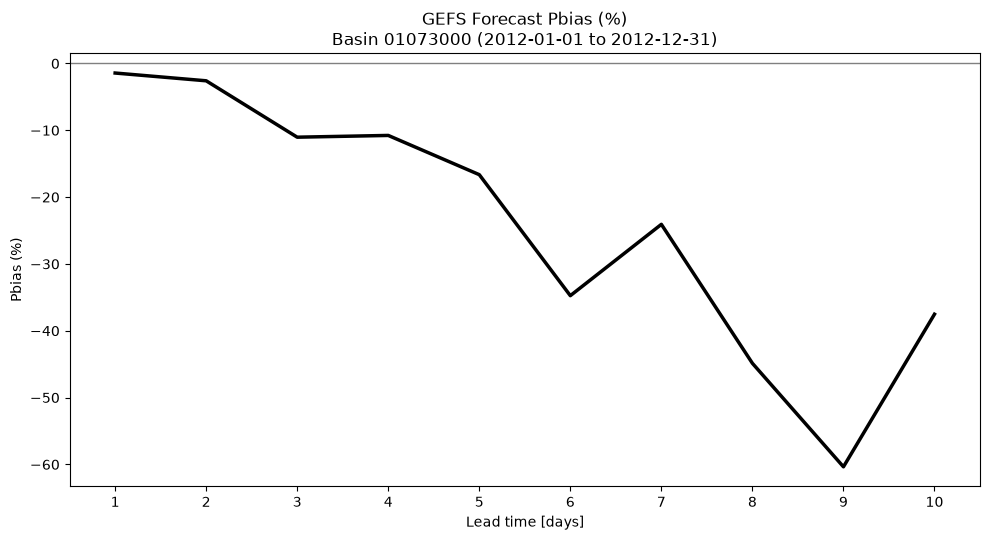

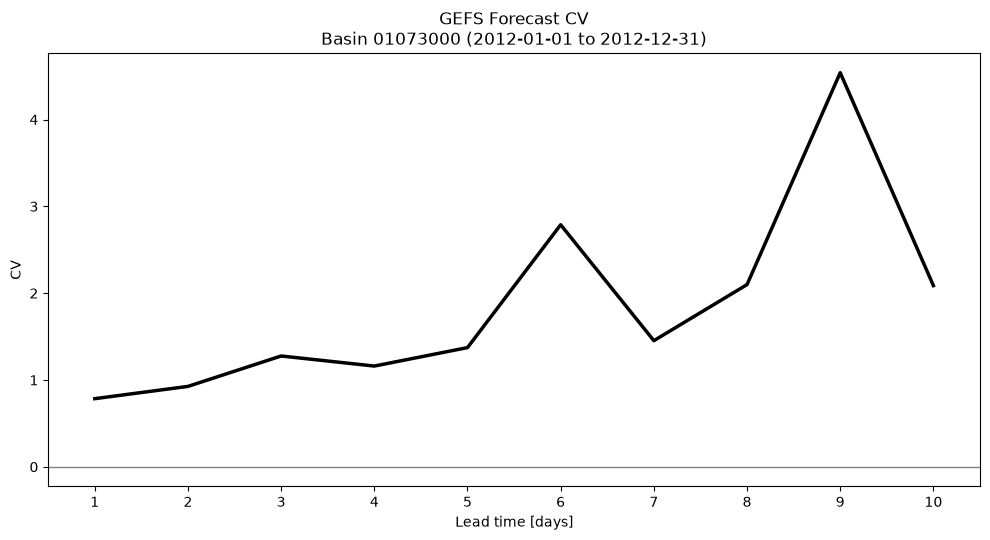

Metrics saved to: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/Evaluation_plots/01073000


In [45]:
ns = gefs.calculate_gefs_ns(ensemble_mean, target_flow, MIN_VALID_CASES)
pbias = gefs.calculate_gefs_pbias(ensemble_mean, target_flow, MIN_VALID_CASES)
cv = gefs.calculate_gefs_cv(ensemble_mean, target_flow, MIN_VALID_CASES)

metric_df = pd.DataFrame({
    "lead_time": np.arange(1, N_LEADS + 1),
    "NS": ns,
    "Pbias_pct": pbias,
    "CV": cv,
})
# display(metric_df)

plot_dir = save_root / "OtherMetrics_simulated_single" / f"{DIAG_BASIN_ID:08d}"
for values, metric_name in [(ns, "NS"), (pbias, "Pbias (%)"), (cv, "CV")]:
    gefs.plot_gefs_metric(
        values, metric_name, save_dir=plot_dir,
        START_DATE=START_DATE, END_DATE=END_DATE, basin_id=DIAG_BASIN_ID,
    )
print("Metrics saved to:", plot_dir)

Available GEFS basins: 113

========== SIMULATION CHECK ==========
Available basins: 113
Loaded from cache: 113
Ready for metrics: 113
Missing cache files: 0
Cache failures: 0
[1/113] 01022500: SUCCESS
[2/113] 01031500: SUCCESS
[3/113] 01047000: SUCCESS
[4/113] 01052500: SUCCESS
[5/113] 01054200: SUCCESS
[6/113] 01055000: SUCCESS
[7/113] 01057000: SUCCESS
[8/113] 01073000: SUCCESS
[9/113] 01078000: SUCCESS
[10/113] 01123000: SUCCESS
[11/113] 01134500: SUCCESS
[12/113] 01137500: SUCCESS
[13/113] 01139000: SUCCESS
[14/113] 01139800: SUCCESS
[15/113] 01142500: SUCCESS
[16/113] 01144000: SUCCESS
[17/113] 01162500: SUCCESS
[18/113] 01169000: SUCCESS
[19/113] 01170100: SUCCESS
[20/113] 01181000: SUCCESS
[21/113] 01187300: SUCCESS
[22/113] 01195100: SUCCESS
[23/113] 01333000: SUCCESS
[24/113] 01350000: SUCCESS
[25/113] 01350080: SUCCESS
[26/113] 01350140: SUCCESS
[27/113] 01365000: SUCCESS
[28/113] 01411300: SUCCESS
[29/113] 01413500: SUCCESS
[30/113] 01414500: SUCCESS
[31/113] 01415000: SUCC

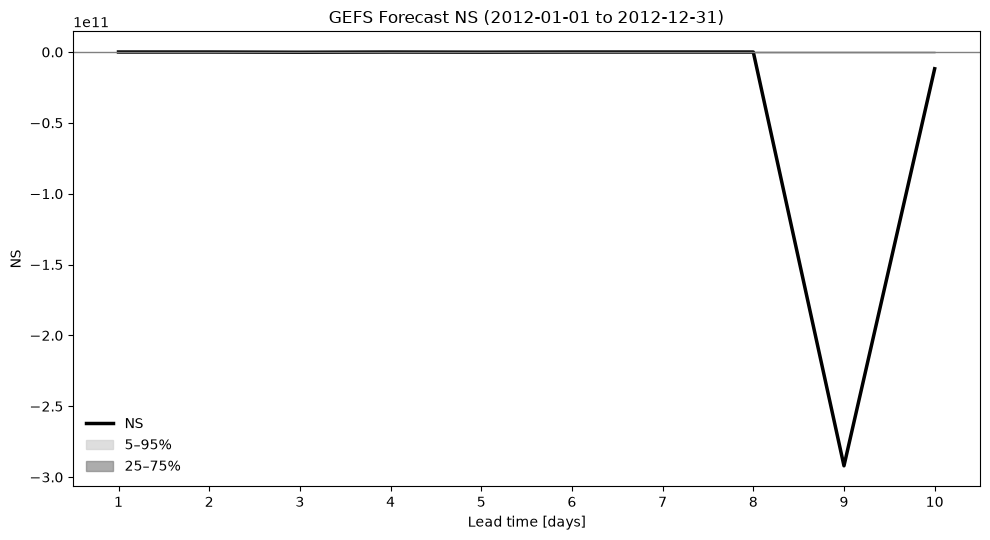

NS figure: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/OtherMetrics_simulated_multiple/GEFS_NS.png


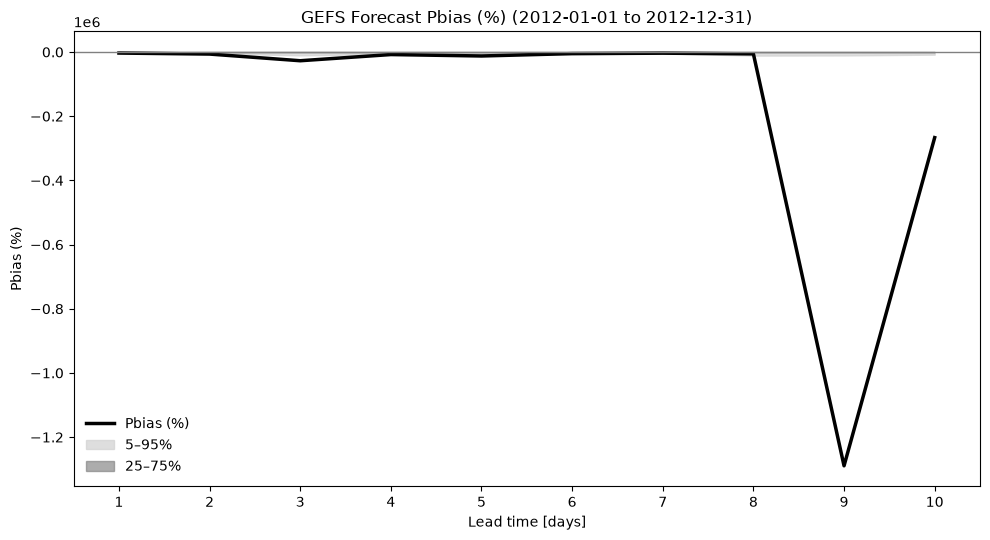

Pbias (%) figure: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/OtherMetrics_simulated_multiple/GEFS_Pbias_(pct).png


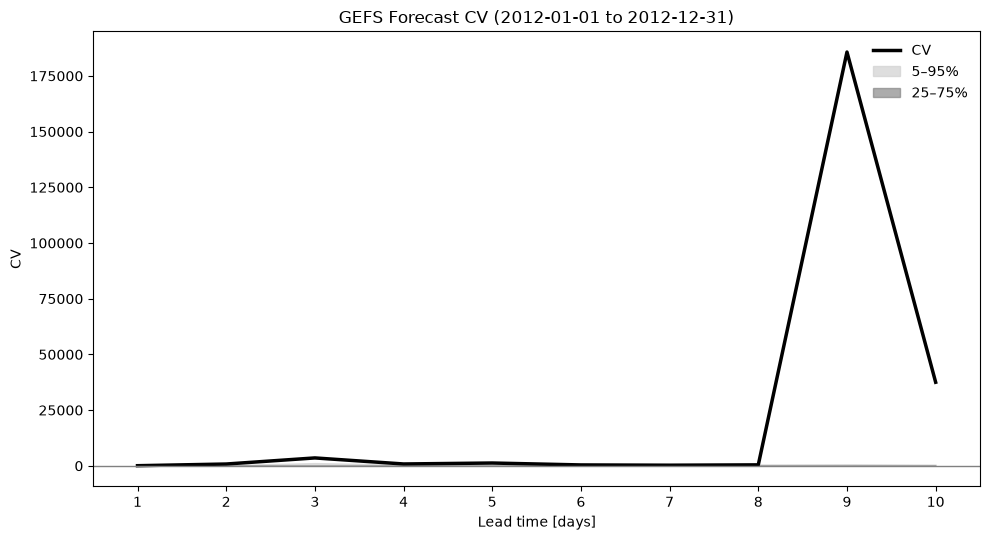

CV figure: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/OtherMetrics_simulated_multiple/GEFS_CV.png

========== COMPLETE ==========
Available basins: 113
Ready for evaluation: 113
Evaluated basins: 113
Failed basins: 0
Output directory: /wendianHome/u/au/ac/zhennanshi/znprojects/generic_deltamodel/example/hydrology/output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/OtherMetrics_simulated_multiple
Detailed CSV: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/OtherMetrics_simulated_multiple/GEFS_metrics_all_basins.csv
Summary CSV: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/OtherMetrics_simulated_multiple/GEFS_metrics_summary.csv


## 7. Plot CRPSS for available multiple basins without taking averages
 
keep your basin selection and CRPSS computation unchanged, but generate the multi-basin plot, including basins that have available forecast folders and calculated CRPSS results

In [37]:
import importlib
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

import tempfunctions
import gefs_crpss as gefs

importlib.reload(tempfunctions)
importlib.reload(gefs)

# 0. Settings
GAGE_NAME_PATH = Path("predownloaded/camels_name.txt")
single_fig_dir = Path(save_root) / "CRPSS_simulated_single"
single_fig_dir.mkdir(parents=True, exist_ok=True)

# 1. Find available GEFS basins
def get_available_gefs_basins(save_root):
    save_root = Path(save_root)

    return sorted(
        int(p.name)
        for p in save_root.iterdir()
        if p.is_dir()
        and p.name.isdigit()
        and len(p.name) == 8
        and any(p.glob("forecast_*.npz"))
    )

available_basins = get_available_gefs_basins(save_root)
print("Available GEFS basins:", len(available_basins))

# 2. Reload all continuous simulations
SIM_DIR = Path(config["sim_dir"]) / "continuous_daymet_reference"

for b in available_basins:
    key = f"{int(b):08d}"

    with np.load(SIM_DIR / f"reference_{key}.npz") as data:
        basin_results[key]["sim"] = data["sim"].copy()

ready_basins = [
    b for b in available_basins
    if "sim" in basin_results.get(f"{b:08d}", {})
]

print("Loaded continuous simulations:", len(ready_basins))

# 3. Generate single-basin CRPSS figures
all_results = []
figure_paths = []
failed_basins = {}

for i, basin_id in enumerate(ready_basins, start=1):
    basin_key = f"{basin_id:08d}"

    print(f"[{i}/{len(ready_basins)}] Processing {basin_key}")

    try:
        # A. Obtain CAMELS basin name
        basin_name = tempfunctions.obtain_gage_name(
            str(GAGE_NAME_PATH), basin_id
        )

        # B. Calculate CRPSS and generate named figure ONCE
        result = gefs.run_gefs_crpss(
            mode="single",
            config=config,
            basin_results=basin_results,
            basin_pool=[basin_id],
            GAGE_ID=basin_id,
            BASIN_NAME=basin_name,
            START_DATE=START_DATE,
            END_DATE=END_DATE,
            PRE=PRE,
            WINDOW=WINDOW,
            POST=POST,
            YEAR=YEAR,
            N_LEADS=N_LEADS,
            N_ENSEMBLES=N_ENSEMBLES,
            LEAD1_OFFSET=LEAD1_OFFSET,
            MIN_VALID_CASES=MIN_VALID_CASES,
            CLIMATOLOGY_YEARS=CLIMATOLOGY_YEARS,
            show_plot=False,
        )

        if not result.get("basin_crpss"):
            raise ValueError("No valid CRPSS results")

        # C. Collect figure generated by run_gefs_crpss()
        # No additional gefs.plot_crpss() call
        figure_path = Path(result["figure_path"])

        if not figure_path.is_file():
            raise FileNotFoundError(figure_path)

        figure_paths.append(figure_path)

        # D. Save CRPSS values for combined CSV
        if result.get("results_df") is not None:
            df_one = result["results_df"].copy()
            df_one["basin_id"] = basin_key
            df_one["basin_name"] = basin_name
            all_results.append(df_one)

        print(f"  SUCCESS: {basin_key} - {basin_name}")

    except Exception as exc:
        failed_basins[basin_key] = str(exc)
        print(f"  FAILED: {basin_key}: {exc}")

print("\n========== FIGURE SUMMARY ==========")
print("Available basins:", len(available_basins))
print("Successful figures:", len(figure_paths))
print("Failed basins:", len(failed_basins))

# 4. Save combined CRPSS CSV
if all_results:
    combined_results_df = pd.concat(all_results, ignore_index=True)
    combined_csv = single_fig_dir / f"CRPSS_single_all_basins_{YEAR}.csv"
    combined_results_df.to_csv(combined_csv, index=False)
    print("Combined CSV:", combined_csv)

# 5. Merge all generated PNGs into ONE PDF
pdf_path = single_fig_dir / f"CRPSS_single_all_basins_{YEAR}.pdf"

if not figure_paths:
    raise ValueError("No figures generated.")

with PdfPages(pdf_path) as pdf:
    for fp in figure_paths:
        with Image.open(fp) as image:
            img = image.convert("RGB")

        width, height = img.size
        fig = plt.figure(figsize=(width / 150, height / 150))

        ax = fig.add_axes([0, 0, 1, 1])
        ax.imshow(img)
        ax.axis("off")

        pdf.savefig(fig, dpi=150)
        plt.close(fig)

print("Merged PDF:", pdf_path)
print("Total PDF pages:", len(figure_paths))

# 6. Save failure report
failed_txt = single_fig_dir / "failed_basins.txt"

with open(failed_txt, "w") as f:
    for basin_id, error in failed_basins.items():
        f.write(f"{basin_id}: {error}\n")

print("Failure report:", failed_txt)

# 7. Final summary
print("\n========== COMPLETE ==========")
print("Available basins:", len(available_basins))
print("Figures generated:", len(figure_paths))
print("Failed basins:", len(failed_basins))
print("PDF:", pdf_path.resolve())

Available GEFS basins: 113
Loaded continuous simulations: 113
[1/113] Processing 01022500
[1/1] 01022500: 362 forecasts
Evaluated: 1; failed: 0
Figure saved to: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_single/CRPSS_01022500_simulated_2012.png
CSV saved to: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_single/CRPSS_single_simulated_2012.csv
  SUCCESS: 01022500 - Narraguagus River at Cherryfield, Maine
[2/113] Processing 01031500
[1/1] 01031500: 362 forecasts
Evaluated: 1; failed: 0
Figure saved to: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_single/CRPSS_01031500_simulated_2012.png
CSV saved to: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_

## 8. Plot other metrics for all available basins 
 
keep your basin selection and CRPSS computation unchanged, but generate the multi-basin plot, including basins that have available forecast folders and calculated CRPSS results
## 8.1 Plot multiple type figure (with taking averages, filter enabled)

Available GEFS basins: 113

========== SIMULATION CHECK ==========
Available basins: 113
Loaded from cache: 113
Ready for metrics: 113
Missing cache files: 0
Cache failures: 0
[1/113] 01022500: SUCCESS
[2/113] 01031500: SUCCESS
[3/113] 01047000: SUCCESS
[4/113] 01052500: SUCCESS
[5/113] 01054200: SUCCESS
[6/113] 01055000: SUCCESS
[7/113] 01057000: SUCCESS
[8/113] 01073000: SUCCESS
[9/113] 01078000: SUCCESS
[10/113] 01123000: SUCCESS
[11/113] 01134500: SUCCESS
[12/113] 01137500: SUCCESS
[13/113] 01139000: SUCCESS
[14/113] 01139800: SUCCESS
[15/113] 01142500: SUCCESS
[16/113] 01144000: SUCCESS
[17/113] 01162500: SUCCESS
[18/113] 01169000: SUCCESS
[19/113] 01170100: SUCCESS
[20/113] 01181000: SUCCESS
[21/113] 01187300: SUCCESS
[22/113] 01195100: SUCCESS
[23/113] 01333000: SUCCESS
[24/113] 01350000: SUCCESS
[25/113] 01350080: SUCCESS
[26/113] 01350140: SUCCESS
[27/113] 01365000: SUCCESS
[28/113] 01411300: SUCCESS
[29/113] 01413500: SUCCESS
[30/113] 01414500: SUCCESS
[31/113] 01415000: SUCC

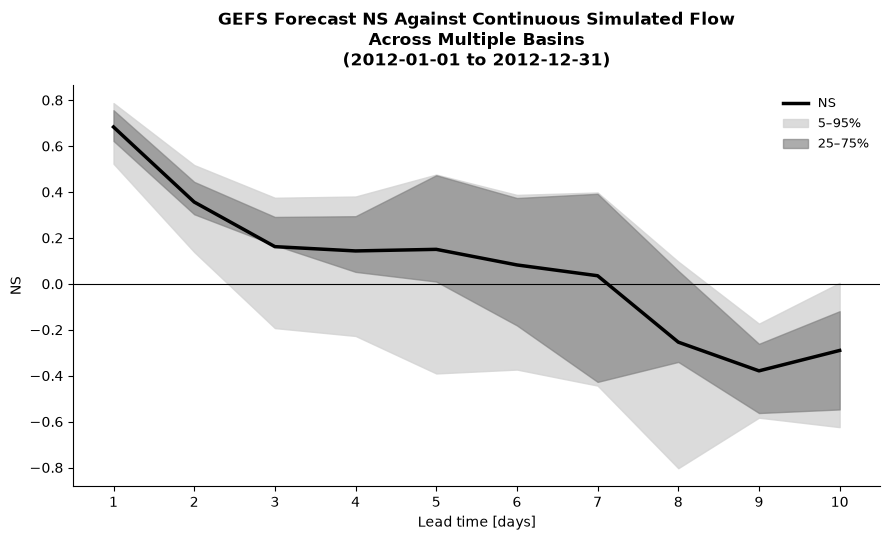

Filtered NS figure: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/OtherMetrics_simulated_multiple/GEFS_NS.png

========== Pbias (%) FILTER ==========
Original basins: 113
Excluded basins: 99
Remaining basins: 14


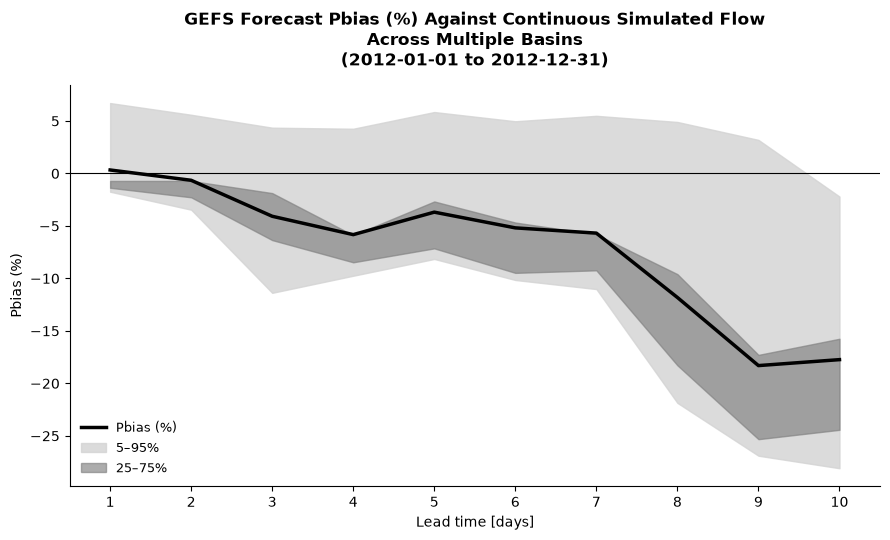

Filtered Pbias (%) figure: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/OtherMetrics_simulated_multiple/GEFS_Pbias_(pct).png

========== CV FILTER ==========
Original basins: 113
Excluded basins: 111
Remaining basins: 2


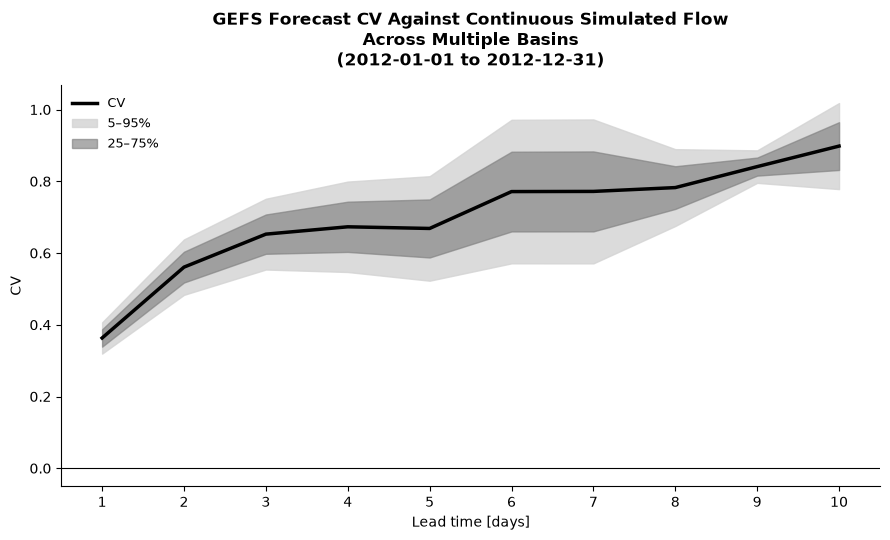

Filtered CV figure: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/OtherMetrics_simulated_multiple/GEFS_CV.png

========== COMPLETE ==========
Originally evaluated basins: 113
NS: 5/113 basins retained
Pbias_pct: 14/113 basins retained
CV: 2/113 basins retained
Output directory: /wendianHome/u/au/ac/zhennanshi/znprojects/generic_deltamodel/example/hydrology/output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/OtherMetrics_simulated_multiple
Original detailed CSV: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/OtherMetrics_simulated_multiple/GEFS_metrics_all_basins.csv
Filtered summary CSV: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/OtherM

In [55]:
import gefs_crpss as gefs

# =====================================================
# 0. Settings
# =====================================================
save_root = Path(save_root)

plot_dir = save_root / "OtherMetrics_simulated_multiple"
plot_dir.mkdir(parents=True, exist_ok=True)

SIM_DIR = Path(config["sim_dir"]) / "continuous_daymet_reference"

# =====================================================
# 1. Find all available GEFS basins
# =====================================================
available_basins = sorted(
    int(p.name)
    for p in save_root.iterdir()
    if p.is_dir()
    and p.name.isdigit()
    and len(p.name) == 8
    and any(p.glob("forecast_*.npz"))
)

print("Available GEFS basins:", len(available_basins))

# =====================================================
# 2. Reload cached continuous HBV simulations
# =====================================================
loaded = []
missing_cache = []
cache_failures = {}

for b in available_basins:
    key = f"{b:08d}"
    cache_file = SIM_DIR / f"reference_{key}.npz"

    if not cache_file.exists():
        missing_cache.append(key)
        continue

    try:
        with np.load(cache_file, allow_pickle=False) as data:
            sim = np.asarray(data["sim"], dtype=float).copy()
            dates = pd.DatetimeIndex(
                pd.to_datetime(data["dates"])
            ).normalize()

        if sim.ndim != 1 or len(sim) != len(dates):
            raise ValueError("Simulation/dates shape mismatch")

        # Create missing basin entry automatically
        basin_results.setdefault(key, {})

        # Validate dates if already present
        if "dates" in basin_results[key]:
            existing_dates = pd.DatetimeIndex(
                pd.to_datetime(basin_results[key]["dates"])
            ).normalize()

            if not existing_dates.equals(dates):
                raise ValueError("Cached dates do not match existing dates")

        basin_results[key]["sim"] = sim
        basin_results[key]["dates"] = dates

        loaded.append(key)

    except Exception as exc:
        cache_failures[key] = str(exc)
        print(f"Cache FAILED {key}: {exc}")

# IMPORTANT: Select metric basins AFTER loading simulations
metric_basins = [
    b for b in available_basins
    if "sim" in basin_results.get(f"{b:08d}", {})
    and "dates" in basin_results.get(f"{b:08d}", {})
]

print("\n========== SIMULATION CHECK ==========")
print("Available basins:", len(available_basins))
print("Loaded from cache:", len(loaded))
print("Ready for metrics:", len(metric_basins))
print("Missing cache files:", len(missing_cache))
print("Cache failures:", len(cache_failures))

if not metric_basins:
    raise ValueError("No basins have valid continuous simulations.")

# =====================================================
# 3. Calculate NS, Pbias, CV for each basin
# =====================================================
all_metrics = []
failed_basins = {}

for i, basin_id in enumerate(metric_basins, 1):
    basin_key = f"{basin_id:08d}"

    try:
        # Existing GEFS forecasts: (I, L, M)
        forecasts, init_dates = gefs.load_basin_forecasts(
            save_root,
            basin_id,
            year=YEAR,
            start_date=START_DATE,
            end_date=END_DATE,
            n_members=N_ENSEMBLES,
            n_leads=N_LEADS,
        )

        # Continuous simulated discharge
        qsim = gefs.simulated_series(
            basin_results, basin_id
        )

        # Target discharge: (I, L)
        # Initial discharge: (I,)
        target_flow, initial_flow = gefs.align_reference(
            qsim, init_dates, N_LEADS, LEAD1_OFFSET
        )

        # Same valid-case mask used by CRPSS
        valid = gefs.valid_forecast_cases(
            forecasts, target_flow, initial_flow
        )

        # Ensemble mean: (I, L)
        with np.errstate(invalid="ignore", over="ignore"):
            ensemble_mean = np.mean(forecasts, axis=2)

        ensemble_mean = np.where(valid, ensemble_mean, np.nan)
        target_flow = np.where(valid, target_flow, np.nan)

        # Lead-wise metrics: (L,)
        ns = gefs.calculate_gefs_ns(
            ensemble_mean, target_flow, MIN_VALID_CASES
        )

        pbias = gefs.calculate_gefs_pbias(
            ensemble_mean, target_flow, MIN_VALID_CASES
        )

        cv = gefs.calculate_gefs_cv(
            ensemble_mean, target_flow, MIN_VALID_CASES
        )

        all_metrics.append(pd.DataFrame({
            "basin_id": basin_key,
            "lead_time": np.arange(1, N_LEADS + 1),
            "NS": ns,
            "Pbias_pct": pbias,
            "CV": cv,
        }))

        print(
            f"[{i}/{len(metric_basins)}] "
            f"{basin_key}: SUCCESS"
        )

    except Exception as exc:
        failed_basins[basin_key] = str(exc)
        print(
            f"[{i}/{len(metric_basins)}] "
            f"{basin_key}: FAILED - {exc}"
        )

if not all_metrics:
    raise ValueError("No basins evaluated successfully.")

# =====================================================
# 4. Save detailed metrics for all basins
# =====================================================
metrics_df = pd.concat(all_metrics, ignore_index=True)

metrics_csv = plot_dir / "GEFS_metrics_all_basins.csv"
metrics_df.to_csv(metrics_csv, index=False)

n_basins = metrics_df["basin_id"].nunique()
print("\nSuccessfully evaluated:", n_basins)


# =====================================================
# 5. Filter outlier basins, calculate spatial statistics,
#    and generate filtered multiple-basin plots
# =====================================================

# Exclude the entire basin if ANY lead violates the threshold
THRESHOLDS = {
    "NS": ("min", -1),          # Remove if any NS < 0
    "Pbias_pct": ("min", -30.0), # Remove if any Pbias < -30%
    "CV": ("max", 1.2),          # Remove if any CV > 1.2
}

summary_rows = []
excluded_rows = []
retained_counts = {}

for metric, metric_name in [
    ("NS", "NS"),
    ("Pbias_pct", "Pbias (%)"),
    ("CV", "CV"),
]:

    pivot = metrics_df.pivot(
        index="basin_id",
        columns="lead_time",
        values=metric,
    ).reindex(columns=np.arange(1, N_LEADS + 1))

    values = pivot.to_numpy(dtype=float)
    basin_ids = pivot.index.to_numpy()

    # -------------------------------------------------
    # A. Basin-level threshold filtering
    # -------------------------------------------------
    rule, threshold = THRESHOLDS[metric]

    if rule == "min":
        outlier_mask = np.any(values < threshold, axis=1)
    else:
        outlier_mask = np.any(values > threshold, axis=1)

    # Also remove basins with no finite values
    no_data_mask = ~np.isfinite(values).any(axis=1)

    exclude_mask = outlier_mask | no_data_mask
    keep_mask = ~exclude_mask

    filtered_values = values[keep_mask]
    retained_ids = basin_ids[keep_mask]
    excluded_ids = basin_ids[exclude_mask]

    retained_counts[metric] = len(retained_ids)

    print(f"\n========== {metric_name} FILTER ==========")
    print("Original basins:", len(basin_ids))
    print("Excluded basins:", len(excluded_ids))
    print("Remaining basins:", len(retained_ids))

    # Record excluded basins and violating lead times
    for idx in np.where(exclude_mask)[0]:
        if rule == "min":
            bad_leads = np.where(values[idx] < threshold)[0] + 1
        else:
            bad_leads = np.where(values[idx] > threshold)[0] + 1

        excluded_rows.append({
            "metric": metric,
            "basin_id": basin_ids[idx],
            "threshold": threshold,
            "rule": rule,
            "reason": (
                "Threshold violation"
                if outlier_mask[idx] else "No finite values"
            ),
            "violating_leads": ",".join(map(str, bad_leads)),
        })

    # Save filtered detailed values for this metric
    filtered_df = metrics_df[
        metrics_df["basin_id"].isin(retained_ids)
    ][["basin_id", "lead_time", metric]].copy()

    filtered_df.to_csv(
        plot_dir / f"GEFS_{metric}_filtered_basins.csv",
        index=False,
    )

    if len(retained_ids) == 0:
        print(f"No basins remaining for {metric_name}; skipping plot")
        continue

    # -------------------------------------------------
    # B. Calculate spatial statistics AFTER filtering
    # -------------------------------------------------
    mean = []
    p05, p25, p75, p95 = [], [], [], []

    for col in filtered_values.T:
        finite = col[np.isfinite(col)]

        if finite.size:
            mean.append(float(np.mean(finite)))
            q = np.percentile(finite, [5, 25, 75, 95])
        else:
            mean.append(np.nan)
            q = [np.nan] * 4

        p05.append(q[0])
        p25.append(q[1])
        p75.append(q[2])
        p95.append(q[3])

    # -------------------------------------------------
    # C. Plot filtered spatial results
    # -------------------------------------------------
    figure_path = gefs.plot_gefs_metric(
        values=np.asarray(mean),
        metric_name=metric_name,
        save_dir=plot_dir,
        START_DATE=START_DATE,
        END_DATE=END_DATE,
        percentiles=(
            np.asarray(p05),
            np.asarray(p25),
            np.asarray(p75),
            np.asarray(p95),
        ),
        show_plot=True,
    )

    # -------------------------------------------------
    # D. Save filtered spatial statistics
    # -------------------------------------------------
    for j in range(N_LEADS):
        summary_rows.append({
            "metric": metric,
            "lead_time": j + 1,
            "mean": mean[j],
            "p05": p05[j],
            "p25": p25[j],
            "p75": p75[j],
            "p95": p95[j],
            "n_retained_basins": len(retained_ids),
            "n_valid_basins": int(
                np.isfinite(filtered_values[:, j]).sum()
            ),
        })

    print(f"Filtered {metric_name} figure: {figure_path}")

# =====================================================
# 6. Save filtered summaries and excluded basin report
# =====================================================

summary_df = pd.DataFrame(summary_rows)
summary_csv = plot_dir / "GEFS_metrics_summary_filtered.csv"
summary_df.to_csv(summary_csv, index=False)

excluded_df = pd.DataFrame(
    excluded_rows,
    columns=[
        "metric", "basin_id", "threshold",
        "rule", "reason", "violating_leads"
    ],
)
excluded_csv = plot_dir / "GEFS_metrics_excluded_basins.csv"
excluded_df.to_csv(excluded_csv, index=False)

failed_csv = plot_dir / "GEFS_metrics_failed_basins.csv"
pd.DataFrame(
    [{"basin_id": k, "error": v}
     for k, v in failed_basins.items()],
    columns=["basin_id", "error"],
).to_csv(failed_csv, index=False)

# =====================================================
# 7. Final summary
# =====================================================
print("\n========== COMPLETE ==========")
print("Originally evaluated basins:", n_basins)

for metric, count in retained_counts.items():
    print(f"{metric}: {count}/{n_basins} basins retained")

print("Output directory:", plot_dir.resolve())
print("Original detailed CSV:", metrics_csv)
print("Filtered summary CSV:", summary_csv)
print("Excluded basin report:", excluded_csv)

## 8.2 Plot single type figure (without taking averages), merge into one pdf

In [53]:
import importlib
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

import gefs_crpss as gefs
import tempfunctions

importlib.reload(gefs)
importlib.reload(tempfunctions)

# =====================================================
# 0. Settings
# =====================================================
save_root = Path(save_root)
plot_dir = save_root / "OtherMetrics_simulated_single"
plot_dir.mkdir(parents=True, exist_ok=True)

SIM_DIR = Path(config["sim_dir"]) / "continuous_daymet_reference"
GAGE_NAME_PATH = Path("predownloaded/camels_name.txt")

metric_names = [
    ("NS", "NS"),
    ("Pbias_pct", "Pbias (%)"),
    ("CV", "CV"),
]

# =====================================================
# 1. Find available GEFS basins
# =====================================================
available_basins = sorted(
    int(p.name)
    for p in save_root.iterdir()
    if p.is_dir()
    and p.name.isdigit()
    and len(p.name) == 8
    and any(p.glob("forecast_*.npz"))
)

print("Available GEFS basins:", len(available_basins))

# =====================================================
# 2. Recalculate NS, Pbias and CV for each basin
# =====================================================
all_metrics = []
figure_paths = []
failed_basins = {}
failed_figures = {}

for i, basin_id in enumerate(available_basins, start=1):
    basin_key = f"{basin_id:08d}"

    print(f"[{i}/{len(available_basins)}] Processing {basin_key}")

    try:
        # A. Obtain CAMELS basin name
        basin_name = tempfunctions.obtain_gage_name(
            str(GAGE_NAME_PATH), basin_id
        )

        # B. Load cached continuous HBV simulation
        cache_file = SIM_DIR / f"reference_{basin_key}.npz"

        with np.load(cache_file, allow_pickle=False) as data:
            sim = np.asarray(data["sim"], dtype=float).copy()
            dates = pd.DatetimeIndex(
                pd.to_datetime(data["dates"])
            ).normalize()

        if sim.ndim != 1 or len(sim) != len(dates):
            raise ValueError("Simulation/dates mismatch")

        basin_results.setdefault(basin_key, {})
        basin_results[basin_key]["sim"] = sim
        basin_results[basin_key]["dates"] = dates

        # C. Load existing GEFS forecasts (I, L, M)
        forecasts, init_dates = gefs.load_basin_forecasts(
            save_root,
            basin_id,
            year=YEAR,
            start_date=START_DATE,
            end_date=END_DATE,
            n_members=N_ENSEMBLES,
            n_leads=N_LEADS,
        )

        # D. Align continuous simulation to forecast dates
        qsim = gefs.simulated_series(
            basin_results, basin_id
        )

        target_flow, initial_flow = gefs.align_reference(
            qsim, init_dates, N_LEADS, LEAD1_OFFSET
        )

        # E. Same valid-case mask as CRPSS
        valid = gefs.valid_forecast_cases(
            forecasts, target_flow, initial_flow
        )

        # F. Calculate ensemble mean (I, L)
        with np.errstate(invalid="ignore", over="ignore"):
            ensemble_mean = np.mean(forecasts, axis=2)

        ensemble_mean = np.where(valid, ensemble_mean, np.nan)
        target_flow = np.where(valid, target_flow, np.nan)

        # G. Recalculate metrics (L,)
        ns = gefs.calculate_gefs_ns(
            ensemble_mean, target_flow, MIN_VALID_CASES
        )

        pbias = gefs.calculate_gefs_pbias(
            ensemble_mean, target_flow, MIN_VALID_CASES
        )

        cv = gefs.calculate_gefs_cv(
            ensemble_mean, target_flow, MIN_VALID_CASES
        )

        # H. Save metric values in memory
        metric_df = pd.DataFrame({
            "basin_id": basin_key,
            "basin_name": basin_name,
            "lead_time": np.arange(1, N_LEADS + 1),
            "NS": ns,
            "Pbias_pct": pbias,
            "CV": cv,
            "n_valid": valid.sum(axis=0),
        })

        all_metrics.append(metric_df)

        print(f"  Metrics calculated: {len(init_dates)} forecasts")

        # =================================================
        # I. Generate three named figures for this basin
        # =================================================
        basin_dir = plot_dir / basin_key
        basin_dir.mkdir(parents=True, exist_ok=True)

        for values, metric_name in [
            (ns, "NS"),
            (pbias, "Pbias (%)"),
            (cv, "CV"),
        ]:
            try:
                if not np.isfinite(values).any():
                    raise ValueError("No finite values")

                figure_path = gefs.plot_gefs_metric(
                    values,
                    metric_name,
                    save_dir=basin_dir,
                    START_DATE=START_DATE,
                    END_DATE=END_DATE,
                    basin_id=basin_id,
                    basin_name=basin_name,
                    show_plot=False,
                )

                if figure_path is None:
                    raise ValueError("No figure path returned")

                figure_path = Path(figure_path)

                if not figure_path.is_file():
                    raise FileNotFoundError(figure_path)

                figure_paths.append(figure_path)

            except Exception as exc:
                failed_figures[f"{basin_key}_{metric_name}"] = str(exc)
                print(f"  Plot FAILED {metric_name}: {exc}")

        print(f"  SUCCESS: {basin_key} - {basin_name}")

    except Exception as exc:
        failed_basins[basin_key] = str(exc)
        print(f"  FAILED: {basin_key}: {exc}")

if not all_metrics:
    raise ValueError("No basin metrics calculated successfully.")

# =====================================================
# 3. Save combined metrics CSV
# =====================================================
metrics_df = pd.concat(all_metrics, ignore_index=True)

metrics_csv = plot_dir / f"GEFS_metrics_all_basins_{YEAR}.csv"
metrics_df.to_csv(metrics_csv, index=False)

print("\n========== METRICS SUMMARY ==========")
print("Successfully evaluated:", metrics_df["basin_id"].nunique())
print("Metric CSV:", metrics_csv)

# =====================================================
# 4. Merge generated PNGs into one PDF
#    Three pages per basin: NS, Pbias, CV
# =====================================================
pdf_path = plot_dir / f"GEFS_NS_Pbias_CV_all_basins_{YEAR}.pdf"

if not figure_paths:
    raise ValueError("No figures generated.")

with PdfPages(pdf_path) as pdf:
    for fp in figure_paths:
        with Image.open(fp) as image:
            img = image.convert("RGB")

        width, height = img.size

        fig = plt.figure(figsize=(width / 150, height / 150))
        ax = fig.add_axes([0, 0, 1, 1])
        ax.imshow(img)
        ax.axis("off")

        pdf.savefig(fig, dpi=150)
        plt.close(fig)

print("Merged PDF:", pdf_path)
print("Total PDF pages:", len(figure_paths))

# =====================================================
# 5. Save failure reports
# =====================================================
failed_txt = plot_dir / "failed_metrics.txt"

with open(failed_txt, "w") as f:
    for basin_id, error in failed_basins.items():
        f.write(f"{basin_id}: {error}\n")
    for figure_id, error in failed_figures.items():
        f.write(f"{figure_id}: Plot failed: {error}\n")

# =====================================================
# 6. Final summary
# =====================================================
print("\n========== COMPLETE ==========")
print("Available basins:", len(available_basins))
print("Evaluated basins:", metrics_df["basin_id"].nunique())
print("Figures generated:", len(figure_paths))
print("Failed basins:", len(failed_basins))
print("Failed figures:", len(failed_figures))
print("PDF pages:", len(figure_paths))
print("Output directory:", plot_dir.resolve())
print("CSV:", metrics_csv.resolve())
print("PDF:", pdf_path.resolve())

Available GEFS basins: 113
[1/113] Processing 01022500
  Metrics calculated: 362 forecasts
  SUCCESS: 01022500 - Narraguagus River at Cherryfield, Maine
[2/113] Processing 01031500
  Metrics calculated: 362 forecasts
  SUCCESS: 01031500 - Piscataquis River near Dover-Foxcroft, Maine
[3/113] Processing 01047000
  Metrics calculated: 362 forecasts
  SUCCESS: 01047000 - Carrabassett River near North Anson, Maine
[4/113] Processing 01052500
  Metrics calculated: 362 forecasts
  SUCCESS: 01052500 - Diamond River near Wentworth Location, NH
[5/113] Processing 01054200
  Metrics calculated: 362 forecasts
  SUCCESS: 01054200 - Wild River at Gilead, Maine
[6/113] Processing 01055000
  Metrics calculated: 362 forecasts
  SUCCESS: 01055000 - Swift River near Roxbury, Maine
[7/113] Processing 01057000
  Metrics calculated: 362 forecasts
  SUCCESS: 01057000 - Little Androscoggin River near South Paris, Maine
[8/113] Processing 01073000
  Metrics calculated: 362 forecasts
  SUCCESS: 01073000 - OYSTE